# Noisy Signal Population

In [2]:
import numpy as np

t=np.linspace(
    start =0, #start time
    stop = 10, #stop time
    num = 200 # number of points
)

f=2.0 #frequency of the signal
a=3.0 #amplitude of the signal

#generate the clean sinusoidal signal

y_pure=a*np.sin(2*np.pi*f*t) #pure signal

# add gaussian noise to the signal
gaussian_noise = np.random.normal(
    loc=0.0, #mean of the noise
    scale=.6, #standard deviation of the noise
    size=len(t) #size of the noise array
)

# generate the noisy signal by adding the noise to the pure signal

y_noisy = y_pure + gaussian_noise

print("Harmonic signal with Gaussian noise generated successfully.")
print("Time Domain Array Length: ", len(t))
print(f"Pure Signal Array Range: " ,{y_pure.min()} ,"to", {y_pure.max()})
print(f"Noisy Signal Array Range: " ,{y_noisy.min()} ,"to", {y_noisy.max()})
print(f"Calculated noise variance: " ,{np.var(gaussian_noise)})



Harmonic signal with Gaussian noise generated successfully.
Time Domain Array Length:  200
Pure Signal Array Range:  {np.float64(-2.9999065406824688)} to {np.float64(2.9999065406824688)}
Noisy Signal Array Range:  {np.float64(-4.208534241016771)} to {np.float64(4.179901487661974)}
Calculated noise variance:  {np.float64(0.34959397217673716)}


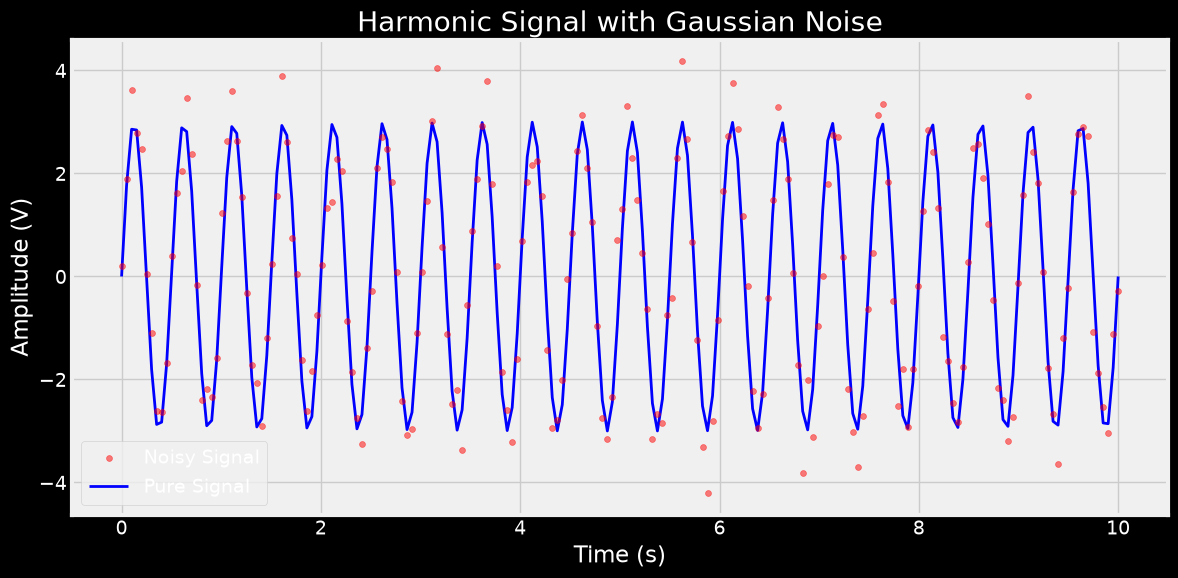

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
# whiteboard theme
plt.style.use("fivethirtyeight")
plt.scatter(
    x=t,
    y=y_noisy,
    s=18,
    color="red",
    alpha=0.5,
    label="Noisy Signal",
    zorder=2
)


# add waves
plt.plot(t,y_pure,color="blue",label="Pure Signal",zorder=1, linewidth=2)
plt.title("Harmonic Signal with Gaussian Noise")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.tight_layout()
plt.show()

# Exponential Decay Signal Population

In [8]:
# Generate Decay signal

t_decay=np.linspace(
    start =0, #start time
    stop = 5, #stop time
    num = 100 # number of points
)

N0=5.0 #initial amplitude of the signal
decay_rate=0.8 #decay rate of the signal

#generate the decaying exponential signal
y_decay = N0 * np.exp(-decay_rate*t_decay) #decaying signal

#generate uniform noise to be added to the decaying signal

uniform_noise = np.random.uniform(
    low=-0.5, #lower bound of the noise
    high=0.5, #upper bound of the noise
    size=len(t_decay) #size of the noise array
)
# genrate the noisy decay signal by adding the unifrom noise to the pure decay signal

y_decay_noisy = y_decay + uniform_noise

print("Decaying signal with uniform noise generated successfully.")
print(f"initial pure value at t=0: {y_decay[0]}")
print(f"Final pure value at t=5: {y_decay[-1]}")
print(f"Uniform Error Bounds: {uniform_noise.min()} to {uniform_noise.max()}")

Decaying signal with uniform noise generated successfully.
initial pure value at t=0: 5.0
Final pure value at t=5: 0.0915781944436709
Uniform Error Bounds: -0.4972686319702022 to 0.48646725180348294


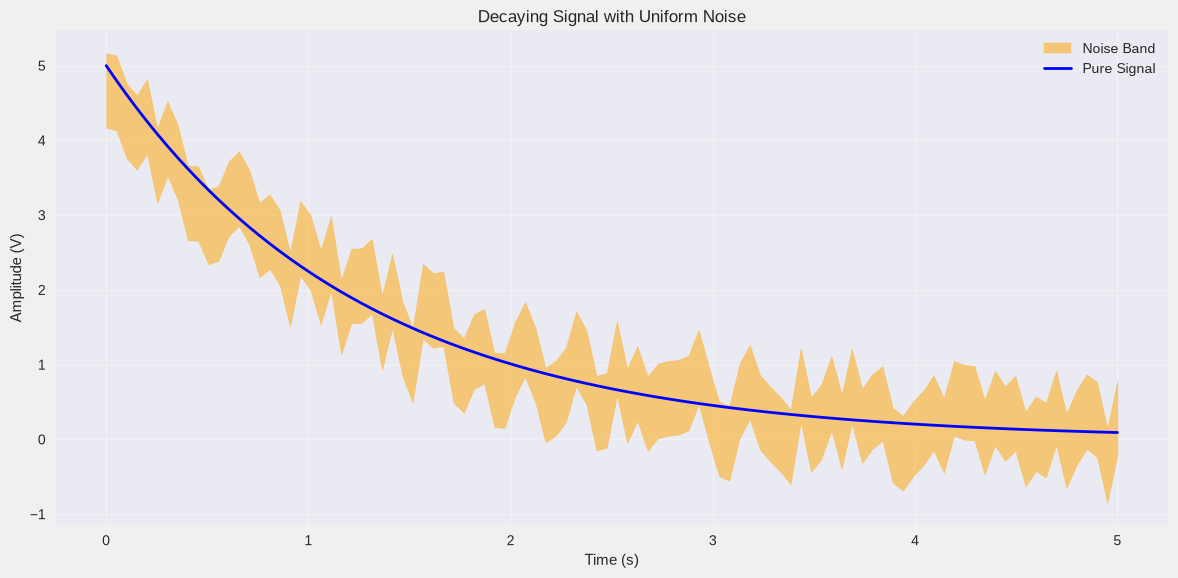

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.style.use("seaborn-v0_8")

# Noise band
plt.fill_between(
    t_decay,
    y_decay_noisy - 0.5,
    y_decay_noisy + 0.5,
    color="orange",
    alpha=0.5,
    label="Noise Band",
    zorder=2import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.style.use("seaborn-v0_8")

# Noise band
plt.fill_between(
    t_decay,
    y_decay_noisy - 0.5,
    y_decay_noisy + 0.5,
    color="orange",
    alpha=0.5,
    label="Noise Band",
    zorder=2
)

# Pure decaying signal
plt.plot(
    t_decay,
    y_decay,
    color="blue",
    linewidth=2,
    label="Pure Signal",
    zorder=3
)

plt.title("Decaying Signal with Uniform Noise")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
)

# Pure decaying signal
plt.plot(
    t_decay,
    y_decay,
    color="blue",
    linewidth=2,
    label="Pure Signal",
    zorder=3
)

plt.title("Decaying Signal with Uniform Noise")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Polynomial Function + Sparse Outliers ( Salt & Pepper / Impulse Noise)

### Overview & Purpose

- Models smooth polynnomial trends contaminated with sparse outliers, often referred to as salt-and-pepper or impulse noise. This is useful for testing robust regression techniques and outlier detection methods.
- The noise is generated by randomly adding or removing data points from the original data.
- The noise is added or removed at random,

=== Polynomial Function + Sparse Outliers ===
Total Data Points: 100
Injected Outliers: 8
Outlier Indices: [22 24 95 36 73  5 83  2]
Outlier Magnitudes: [ 1.35153614  1.61206287 -1.90351652  0.19941529  0.35106642 -1.2103429
  7.43426344 -2.25205974]
Clean Data Mean: 0.64


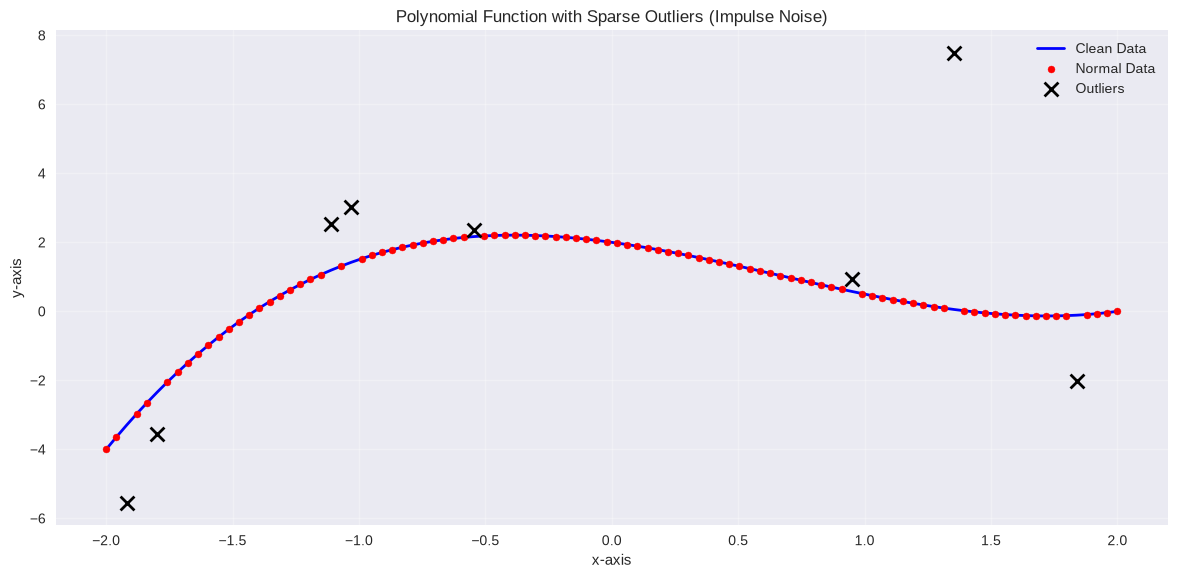

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Generate x values
x_poly = np.linspace(
    start=-2.0,
    stop=2.0,
    num=100
)

# Clean polynomial function
y_poly_clean = (
    0.5 * (x_poly ** 3)
    - (x_poly ** 2)
    - x_poly
    + 2
)

# Create a copy for corrupted data
y_poly_corrupted = y_poly_clean.copy()

# Select 8% of the data points as outliers
num_outliers = int(0.08 * len(x_poly))

outlier_indices = np.random.choice(
    a=len(x_poly),
    size=num_outliers,
    replace=False
)

# Generate random impulse spikes
spikes_magnitude = np.random.uniform(
    low=-4.0,
    high=8.0,
    size=num_outliers
)

# Inject spikes
y_poly_corrupted[outlier_indices] += spikes_magnitude

# Print information
print("=== Polynomial Function + Sparse Outliers ===")
print(f"Total Data Points: {len(x_poly)}")
print(f"Injected Outliers: {num_outliers}")
print("Outlier Indices:", outlier_indices)
print("Outlier Magnitudes:", spikes_magnitude)
print(f"Clean Data Mean: {y_poly_clean.mean():.2f}")


# -------------------------
# Plot
# -------------------------

plt.figure(figsize=(12, 6))
plt.style.use("seaborn-v0_8")

# Clean polynomial
plt.plot(
    x_poly,
    y_poly_clean,
    color="blue",
    linewidth=2,
    label="Clean Data",
    zorder=2
)

# Identify normal points
normal_mask = np.ones_like(
    y_poly_clean,
    dtype=bool
)

normal_mask[outlier_indices] = False

# Normal corrupted data
plt.scatter(
    x_poly[normal_mask],
    y_poly_corrupted[normal_mask],
    color="red",
    s=25,
    label="Normal Data",
    zorder=3
)

# Actual outlier spikes
plt.scatter(
    x_poly[outlier_indices],
    y_poly_corrupted[outlier_indices],
    color="black",
    marker="x",
    s=100,
    linewidth=2,
    label="Outliers",
    zorder=4
)

plt.title(
    "Polynomial Function with Sparse Outliers "
    "(Impulse Noise)"
)

plt.xlabel("x-axis")
plt.ylabel("y-axis")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Multi component Composite Signal + Heteroscedastic Noise

## Overview & Purpose
- This example demonstrates a composite signal composed of multiple sinusoidal components, each with different frequencies and amplitudes. The signal is contaminated with heteroscedastic noise, where the noise variance changes over time. This is useful for testing signal processing techniques and understanding how noise characteristics can affect signal analysis.
- Generates complex real-world scenarios where the noise level is not constant, simulating conditions like sensor drift or environmental changes.

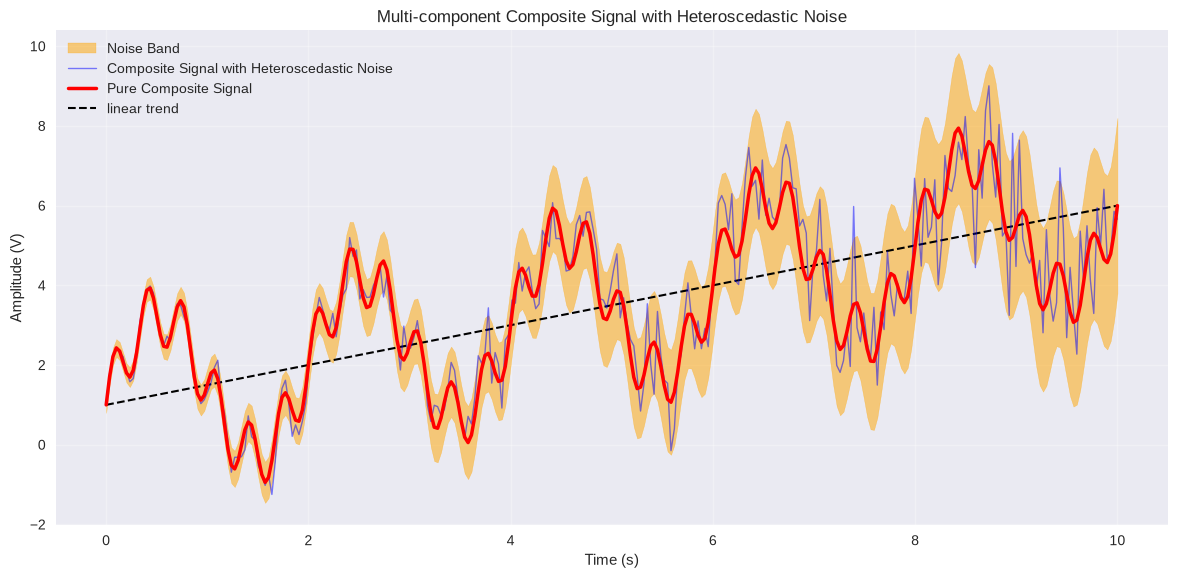

In [26]:
t_comp = np.linspace(
    start = 0,
    stop = 10,
    num = 300
)

trend = 0.5 * t_comp + 1.0  # Linear trend component

harmonics = 2.0 * np.sin(2 * np.pi * 0.5 * t_comp) + 0.8 * np.sin(2 * np.pi * 3 * t_comp)

s_pure = trend + harmonics

sigma_t = 0.1 + 0.1 * t_comp  # Noise standard deviation increases over time

hetero_noise = np.random.normal(
    loc=0.0,
    scale=1.0,
    size=len(t_comp)
) * sigma_t

y_composite = s_pure + hetero_noise

plt.figure(figsize=(12, 6))
plt.style.use("seaborn-v0_8")

plt.fill_between(
    x = t_comp,
    y1 = s_pure - 2 * sigma_t,
    y2 = s_pure + 2 * sigma_t,
    color = "orange",
    alpha = 0.5,
    label = "Noise Band",
    zorder = 2
)

plt.plot(
    t_comp,
    y_composite,
    color = "blue",
    linewidth = 1.0,
    alpha = 0.5,
    label = "Composite Signal with Heteroscedastic Noise",
    zorder = 3
)

plt.plot(
    t_comp,
    s_pure,
    color = "red",
    linewidth = 2.5,
    label = "Pure Composite Signal",
    zorder = 4
)

plt.plot(
    t_comp,
    trend,
    "k--",
    linewidth = 1.5,
    label = "linear trend",
)

plt.title("Multi-component Composite Signal with Heteroscedastic Noise")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()